# 7.12 ROC·PR 곡선과 확률 보정 상태

wine.csv는 178행입니다. scikit-learn 내장 Wine 데이터(load_wine), UCI Wine에서 유래한 178개 관측. 생성 자료 아님. 13개 연속형 화학 분석 특성과 target(0,1,2). 7장은 target==0을 양성으로 재정의한다. 물리 단위는 원 출처 설명을 확인한다.

선정 이유: 분류 순위 능력과 확률의 신뢰도를 다른 관점으로 읽는다.

커널을 다시 시작한 뒤 각 셀을 위에서 아래로 실행합니다. 코드에는 가져오기와 함수 정의도 포함되어 있습니다.

## 셀 1 라이브러리 가져오기

가져오기(Import) 문장으로 경로 객체(Path)를 연결합니다. 이 셀에서는 자료를 학습하지 않습니다.

가져오기(Import) 문장으로 자바스크립트 객체 표기법(JavaScript Object Notation, JSON) 도구를 연결합니다. 이 셀에서는 자료를 학습하지 않습니다.

가져오기(Import) 문장으로 수치 배열 도구 넘파이(Numerical Python, NumPy)의 별칭 np를 연결합니다. 이 셀에서는 자료를 학습하지 않습니다.

가져오기(Import) 문장으로 자료 표 도구 판다스(pandas)의 별칭 pd를 연결합니다. 이 셀에서는 자료를 학습하지 않습니다.

가져오기(Import) 문장으로 맷플롯립 파이플롯(Matplotlib Pyplot)의 별칭 plt를 연결합니다. 이 셀에서는 자료를 학습하지 않습니다.

가져오기(Import) 문장으로 셀 출력 표시 함수(display), 이미지 표시 객체(IPython Image)를 연결합니다. 이 셀에서는 자료를 학습하지 않습니다.

가져오기(Import) 문장으로 훈련 평가 분리 함수(Train Test Split)를 연결합니다. 이 셀에서는 자료를 학습하지 않습니다.

가져오기(Import) 문장으로 처리 단계 연결 함수(Make Pipeline)를 연결합니다. 이 셀에서는 자료를 학습하지 않습니다.

가져오기(Import) 문장으로 표준화 변환기(Standard Scaler)를 연결합니다. 이 셀에서는 자료를 학습하지 않습니다.

가져오기(Import) 문장으로 로지스틱 회귀 분류기(Logistic Regression)를 연결합니다. 이 셀에서는 자료를 학습하지 않습니다.

가져오기(Import) 문장으로 roc_curve 기능, precision_recall_curve 기능, roc_auc_score 기능, average_precision_score 기능, brier_score_loss 기능를 연결합니다. 이 셀에서는 자료를 학습하지 않습니다.

가져오기(Import) 문장으로 calibration_curve 기능를 연결합니다. 이 셀에서는 자료를 학습하지 않습니다.

In [1]:
# 가져오기(Import) 문장으로 경로 객체(Path)를 연결합니다. 이 셀에서는 자료를 학습하지 않습니다.
from pathlib import Path

# 가져오기(Import) 문장으로 자바스크립트 객체 표기법(JavaScript Object Notation, JSON) 도구를 연결합니다. 이 셀에서는 자료를 학습하지 않습니다.
import json

# 가져오기(Import) 문장으로 수치 배열 도구 넘파이(Numerical Python, NumPy)의 별칭 np를 연결합니다. 이 셀에서는 자료를 학습하지 않습니다.
import numpy as np

# 가져오기(Import) 문장으로 자료 표 도구 판다스(pandas)의 별칭 pd를 연결합니다. 이 셀에서는 자료를 학습하지 않습니다.
import pandas as pd

# 가져오기(Import) 문장으로 맷플롯립 파이플롯(Matplotlib Pyplot)의 별칭 plt를 연결합니다. 이 셀에서는 자료를 학습하지 않습니다.
import matplotlib.pyplot as plt

# 가져오기(Import) 문장으로 셀 출력 표시 함수(display), 이미지 표시 객체(IPython Image)를 연결합니다. 이 셀에서는 자료를 학습하지 않습니다.
from IPython.display import display, Image as NotebookImage

# 가져오기(Import) 문장으로 훈련 평가 분리 함수(Train Test Split)를 연결합니다. 이 셀에서는 자료를 학습하지 않습니다.
from sklearn.model_selection import train_test_split

# 가져오기(Import) 문장으로 처리 단계 연결 함수(Make Pipeline)를 연결합니다. 이 셀에서는 자료를 학습하지 않습니다.
from sklearn.pipeline import make_pipeline

# 가져오기(Import) 문장으로 표준화 변환기(Standard Scaler)를 연결합니다. 이 셀에서는 자료를 학습하지 않습니다.
from sklearn.preprocessing import StandardScaler

# 가져오기(Import) 문장으로 로지스틱 회귀 분류기(Logistic Regression)를 연결합니다. 이 셀에서는 자료를 학습하지 않습니다.
from sklearn.linear_model import LogisticRegression

# 가져오기(Import) 문장으로 roc_curve 기능, precision_recall_curve 기능, roc_auc_score 기능, average_precision_score 기능, brier_score_loss 기능를 연결합니다. 이 셀에서는 자료를 학습하지 않습니다.
from sklearn.metrics import roc_curve,precision_recall_curve,roc_auc_score,average_precision_score,brier_score_loss

# 가져오기(Import) 문장으로 calibration_curve 기능를 연결합니다. 이 셀에서는 자료를 학습하지 않습니다.
from sklearn.calibration import calibration_curve

## 셀 2 입력·계산·출력 확인

그림의 축·제목·범례·표시 범위를 설정합니다. 표시 범위가 계산에 사용한 관측 수를 바꾸는 것은 아닙니다.

변수 HERE를 오른쪽 식으로 계산해 다음 단계에서 사용합니다. 값과 형태(Shape)를 구분하고 앞 셀의 입력이 준비되어 있는지 확인합니다.

변수 CHAPTER를 오른쪽 식으로 계산해 다음 단계에서 사용합니다. 값과 형태(Shape)를 구분하고 앞 셀의 입력이 준비되어 있는지 확인합니다.

입력 폴더(Data Directory, DATA)를 오른쪽 식으로 계산해 다음 단계에서 사용합니다. 값과 형태(Shape)를 구분하고 앞 셀의 입력이 준비되어 있는지 확인합니다.

출력 폴더(Output Directory, OUT)를 오른쪽 식으로 계산해 다음 단계에서 사용합니다. 값과 형태(Shape)를 구분하고 앞 셀의 입력이 준비되어 있는지 확인합니다.

앞 셀의 값을 사용해 OUT.mkdir(parents=True,exist_ok=True) 동작을 수행합니다. 코드에 쓰인 괄호·인자·들여쓰기를 유지합니다.

검증 조건(Assertion)을 확인합니다. 거짓이면 셀을 중단하며 실패를 성공한 결과로 바꾸지 않습니다.

In [2]:
# 그림의 축·제목·범례·표시 범위를 설정합니다. 표시 범위가 계산에 사용한 관측 수를 바꾸는 것은 아닙니다.
plt.rcParams.update({"font.family":"DejaVu Sans","font.size":11,"svg.fonttype":"none","axes.prop_cycle":plt.cycler(color=["black","0.45","0.7"]),"figure.figsize":(7,4.2)})

# 변수 HERE를 오른쪽 식으로 계산해 다음 단계에서 사용합니다. 값과 형태(Shape)를 구분하고 앞 셀의 입력이 준비되어 있는지 확인합니다.
HERE=Path(__file__).resolve().parent if "__file__" in globals() else Path.cwd()

# 변수 CHAPTER를 오른쪽 식으로 계산해 다음 단계에서 사용합니다. 값과 형태(Shape)를 구분하고 앞 셀의 입력이 준비되어 있는지 확인합니다.
CHAPTER=HERE if (HERE/"data").exists() else HERE.parent

# 입력 폴더(Data Directory, DATA)를 오른쪽 식으로 계산해 다음 단계에서 사용합니다. 값과 형태(Shape)를 구분하고 앞 셀의 입력이 준비되어 있는지 확인합니다.
DATA=CHAPTER/"data"

# 출력 폴더(Output Directory, OUT)를 오른쪽 식으로 계산해 다음 단계에서 사용합니다. 값과 형태(Shape)를 구분하고 앞 셀의 입력이 준비되어 있는지 확인합니다.
OUT=HERE/"results"/"sec_12_roc_pr"

# 앞 셀의 값을 사용해 OUT.mkdir(parents=True,exist_ok=True) 동작을 수행합니다. 코드에 쓰인 괄호·인자·들여쓰기를 유지합니다.
OUT.mkdir(parents=True,exist_ok=True)

# 검증 조건(Assertion)을 확인합니다. 거짓이면 셀을 중단하며 실패를 성공한 결과로 바꾸지 않습니다.
assert DATA.exists(), f"장별 data 폴더를 함께 내려받으세요: {DATA}"

## 셀 3 함수와 모듈 정의

그림 저장 함수(figure)를 정의합니다. 실제 현재 그림을 벡터 형식과 300dpi 이미지로 저장하고 노트북에 표시합니다. 함수 정의와 뒤의 실제 호출을 구분합니다.

In [3]:
# 그림 저장 함수(figure)를 정의합니다. 실제 현재 그림을 벡터 형식과 300dpi 이미지로 저장하고 노트북에 표시합니다. 함수 정의와 뒤의 실제 호출을 구분합니다.
def figure(out,name):
    plt.tight_layout()
    plt.savefig(out/(name+".svg"),facecolor="white")
    plt.savefig(out/(name+".png"),dpi=300,facecolor="white")
    if "get_ipython" in globals():display(NotebookImage(filename=str(out/(name+".png"))))
    plt.close()

## 셀 4 함수와 모듈 정의

결과 기록 함수(report)를 정의합니다. 계산된 지표만 JSON과 문자 출력에 기록하며 비유한 수치를 성공값으로 바꾸지 않습니다.

In [4]:
# 결과 기록 함수(report)를 정의합니다. 계산된 지표만 JSON과 문자 출력에 기록하며 비유한 수치를 성공값으로 바꾸지 않습니다.
def report(out,name,metrics):
    text=json.dumps(metrics,ensure_ascii=False,indent=2,allow_nan=False)
    (out/(name+".json")).write_text(text,encoding="utf-8")
    print(text)

## 셀 5 입력·계산·출력 확인

쉼표 구분 자료(Comma Separated Values, CSV)를 읽습니다. 이 실습에서 선정한 입력 파일과 열 이름·목표 열을 확인합니다. 입력 자료의 선정 이유와 실제 행 수는 앞의 자료 설명을 따릅니다.

입력 특성 행렬(Feature Matrix, X)를 오른쪽 식으로 계산해 다음 단계에서 사용합니다. 값과 형태(Shape)를 구분하고 앞 셀의 입력이 준비되어 있는지 확인합니다.

목표값(Target, y)를 오른쪽 식으로 계산해 다음 단계에서 사용합니다. 값과 형태(Shape)를 구분하고 앞 셀의 입력이 준비되어 있는지 확인합니다.

훈련 평가 분리(Train Test Split)를 수행합니다. 행 번호 두 배열이면 앞은 훈련, 뒤는 평가이며 네 배열이면 입력과 목표의 행 대응을 유지합니다. test_size는 평가 비율이고 stratify는 클래스 비율 유지 조건입니다.

변수 m를 오른쪽 식으로 계산해 다음 단계에서 사용합니다. 값과 형태(Shape)를 구분하고 앞 셀의 입력이 준비되어 있는지 확인합니다.

앞 셀의 값을 사용해 m.fit(X.iloc[tr],y.iloc[tr]) 동작을 수행합니다. 코드에 쓰인 괄호·인자·들여쓰기를 유지합니다.

변수 p를 오른쪽 식으로 계산해 다음 단계에서 사용합니다. 값과 형태(Shape)를 구분하고 앞 셀의 입력이 준비되어 있는지 확인합니다.

변수 truth를 오른쪽 식으로 계산해 다음 단계에서 사용합니다. 값과 형태(Shape)를 구분하고 앞 셀의 입력이 준비되어 있는지 확인합니다.

변수 fpr·변수 tpr·변수 _를 오른쪽 식으로 계산해 다음 단계에서 사용합니다. 값과 형태(Shape)를 구분하고 앞 셀의 입력이 준비되어 있는지 확인합니다.

변수 precision·변수 recall·변수 _를 오른쪽 식으로 계산해 다음 단계에서 사용합니다. 값과 형태(Shape)를 구분하고 앞 셀의 입력이 준비되어 있는지 확인합니다.

변수 obs·변수 prob를 오른쪽 식으로 계산해 다음 단계에서 사용합니다. 값과 형태(Shape)를 구분하고 앞 셀의 입력이 준비되어 있는지 확인합니다.

변수 fig·변수 axes를 오른쪽 식으로 계산해 다음 단계에서 사용합니다. 값과 형태(Shape)를 구분하고 앞 셀의 입력이 준비되어 있는지 확인합니다.

앞 셀의 값을 사용해 axes[0].plot(fpr,tpr,"k-") 동작을 수행합니다. 코드에 쓰인 괄호·인자·들여쓰기를 유지합니다.

앞 셀의 값을 사용해 axes[0].plot([0,1],[0,1],"k:") 동작을 수행합니다. 코드에 쓰인 괄호·인자·들여쓰기를 유지합니다.

앞 셀의 값을 사용해 axes[0].set(xlabel="False positive rate",ylabel="True positive rate",title="ROC") 동작을 수행합니다. 코드에 쓰인 괄호·인자·들여쓰기를 유지합니다.

앞 셀의 값을 사용해 axes[1].step(recall,precision,where="post",color="black") 동작을 수행합니다. 코드에 쓰인 괄호·인자·들여쓰기를 유지합니다.

앞 셀의 값을 사용해 axes[1].axhline(truth.mean(),color=".5",ls=":") 동작을 수행합니다. 코드에 쓰인 괄호·인자·들여쓰기를 유지합니다.

In [5]:
# 쉼표 구분 자료(Comma Separated Values, CSV)를 읽습니다. 이 실습에서 선정한 입력 파일과 열 이름·목표 열을 확인합니다. 입력 자료의 선정 이유와 실제 행 수는 앞의 자료 설명을 따릅니다.
f=pd.read_csv(DATA/"wine.csv")

# 입력 특성 행렬(Feature Matrix, X)를 오른쪽 식으로 계산해 다음 단계에서 사용합니다. 값과 형태(Shape)를 구분하고 앞 셀의 입력이 준비되어 있는지 확인합니다.
X=f.drop(columns="target")

# 목표값(Target, y)를 오른쪽 식으로 계산해 다음 단계에서 사용합니다. 값과 형태(Shape)를 구분하고 앞 셀의 입력이 준비되어 있는지 확인합니다.
y=(f.target==0).astype(int)

# 훈련 평가 분리(Train Test Split)를 수행합니다. 행 번호 두 배열이면 앞은 훈련, 뒤는 평가이며 네 배열이면 입력과 목표의 행 대응을 유지합니다. test_size는 평가 비율이고 stratify는 클래스 비율 유지 조건입니다.
tr,te=train_test_split(np.arange(len(f)),test_size=.3,stratify=y,random_state=24)

# 변수 m를 오른쪽 식으로 계산해 다음 단계에서 사용합니다. 값과 형태(Shape)를 구분하고 앞 셀의 입력이 준비되어 있는지 확인합니다.
m=make_pipeline(StandardScaler(),LogisticRegression(C=.1,max_iter=1000))

# 앞 셀의 값을 사용해 m.fit(X.iloc[tr],y.iloc[tr]) 동작을 수행합니다. 코드에 쓰인 괄호·인자·들여쓰기를 유지합니다.
m.fit(X.iloc[tr],y.iloc[tr])

# 변수 p를 오른쪽 식으로 계산해 다음 단계에서 사용합니다. 값과 형태(Shape)를 구분하고 앞 셀의 입력이 준비되어 있는지 확인합니다.
p=m.predict_proba(X.iloc[te])[:,1]

# 변수 truth를 오른쪽 식으로 계산해 다음 단계에서 사용합니다. 값과 형태(Shape)를 구분하고 앞 셀의 입력이 준비되어 있는지 확인합니다.
truth=y.iloc[te]

# 변수 fpr·변수 tpr·변수 _를 오른쪽 식으로 계산해 다음 단계에서 사용합니다. 값과 형태(Shape)를 구분하고 앞 셀의 입력이 준비되어 있는지 확인합니다.
fpr,tpr,_=roc_curve(truth,p)

# 변수 precision·변수 recall·변수 _를 오른쪽 식으로 계산해 다음 단계에서 사용합니다. 값과 형태(Shape)를 구분하고 앞 셀의 입력이 준비되어 있는지 확인합니다.
precision,recall,_=precision_recall_curve(truth,p)

# 변수 obs·변수 prob를 오른쪽 식으로 계산해 다음 단계에서 사용합니다. 값과 형태(Shape)를 구분하고 앞 셀의 입력이 준비되어 있는지 확인합니다.
obs,prob=calibration_curve(truth,p,n_bins=5,strategy="uniform")

# 변수 fig·변수 axes를 오른쪽 식으로 계산해 다음 단계에서 사용합니다. 값과 형태(Shape)를 구분하고 앞 셀의 입력이 준비되어 있는지 확인합니다.
fig,axes=plt.subplots(1,3,figsize=(7.5,3.1))

# 앞 셀의 값을 사용해 axes[0].plot(fpr,tpr,"k-") 동작을 수행합니다. 코드에 쓰인 괄호·인자·들여쓰기를 유지합니다.
axes[0].plot(fpr,tpr,"k-")

# 앞 셀의 값을 사용해 axes[0].plot([0,1],[0,1],"k:") 동작을 수행합니다. 코드에 쓰인 괄호·인자·들여쓰기를 유지합니다.
axes[0].plot([0,1],[0,1],"k:")

# 앞 셀의 값을 사용해 axes[0].set(xlabel="False positive rate",ylabel="True positive rate",title="ROC") 동작을 수행합니다. 코드에 쓰인 괄호·인자·들여쓰기를 유지합니다.
axes[0].set(xlabel="False positive rate",ylabel="True positive rate",title="ROC")

# 앞 셀의 값을 사용해 axes[1].step(recall,precision,where="post",color="black") 동작을 수행합니다. 코드에 쓰인 괄호·인자·들여쓰기를 유지합니다.
axes[1].step(recall,precision,where="post",color="black")

# 앞 셀의 값을 사용해 axes[1].axhline(truth.mean(),color=".5",ls=":") 동작을 수행합니다. 코드에 쓰인 괄호·인자·들여쓰기를 유지합니다.
axes[1].axhline(truth.mean(),color=".5",ls=":")

Out[0]: <matplotlib.lines.Line2D at 0x7f88e05f3fe0>


## 셀 6 입력·계산·출력 확인

앞 셀의 값을 사용해 axes[1].set(xlabel="Recall",ylabel="Precision",title="PR") 동작을 수행합니다. 코드에 쓰인 괄호·인자·들여쓰기를 유지합니다.

앞 셀의 값을 사용해 axes[2].plot(prob,obs,"ko-") 동작을 수행합니다. 코드에 쓰인 괄호·인자·들여쓰기를 유지합니다.

앞 셀의 값을 사용해 axes[2].plot([0,1],[0,1],"k:") 동작을 수행합니다. 코드에 쓰인 괄호·인자·들여쓰기를 유지합니다.

앞 셀의 값을 사용해 axes[2].set(xlabel="Mean probability",ylabel="Positive fraction",title="Calibration") 동작을 수행합니다. 코드에 쓰인 괄호·인자·들여쓰기를 유지합니다.

실제 계산한 그림을 저장하고 표시합니다. 축·기호·범례의 의미는 이 실습의 결과 해설과 대조합니다.

앞 셀의 값을 사용해 pd.DataFrame({"true":truth.to_numpy(),"probability":p}).to_csv(OUT/"roc_pr.csv",index=Fals 동작을 수행합니다. 코드에 쓰인 괄호·인자·들여쓰기를 유지합니다.

실제 계산한 수치를 결과 파일과 셀 출력에 기록합니다. 다른 데이터나 미실행 모델의 성능으로 해석하지 않습니다.

{
  "test_n": 54,
  "prevalence": 0.3333333333333333,
  "ROC_AUC": 1.0,
  "AP": 1.0000000000000002,
  "Brier": 0.027331693273780305
}


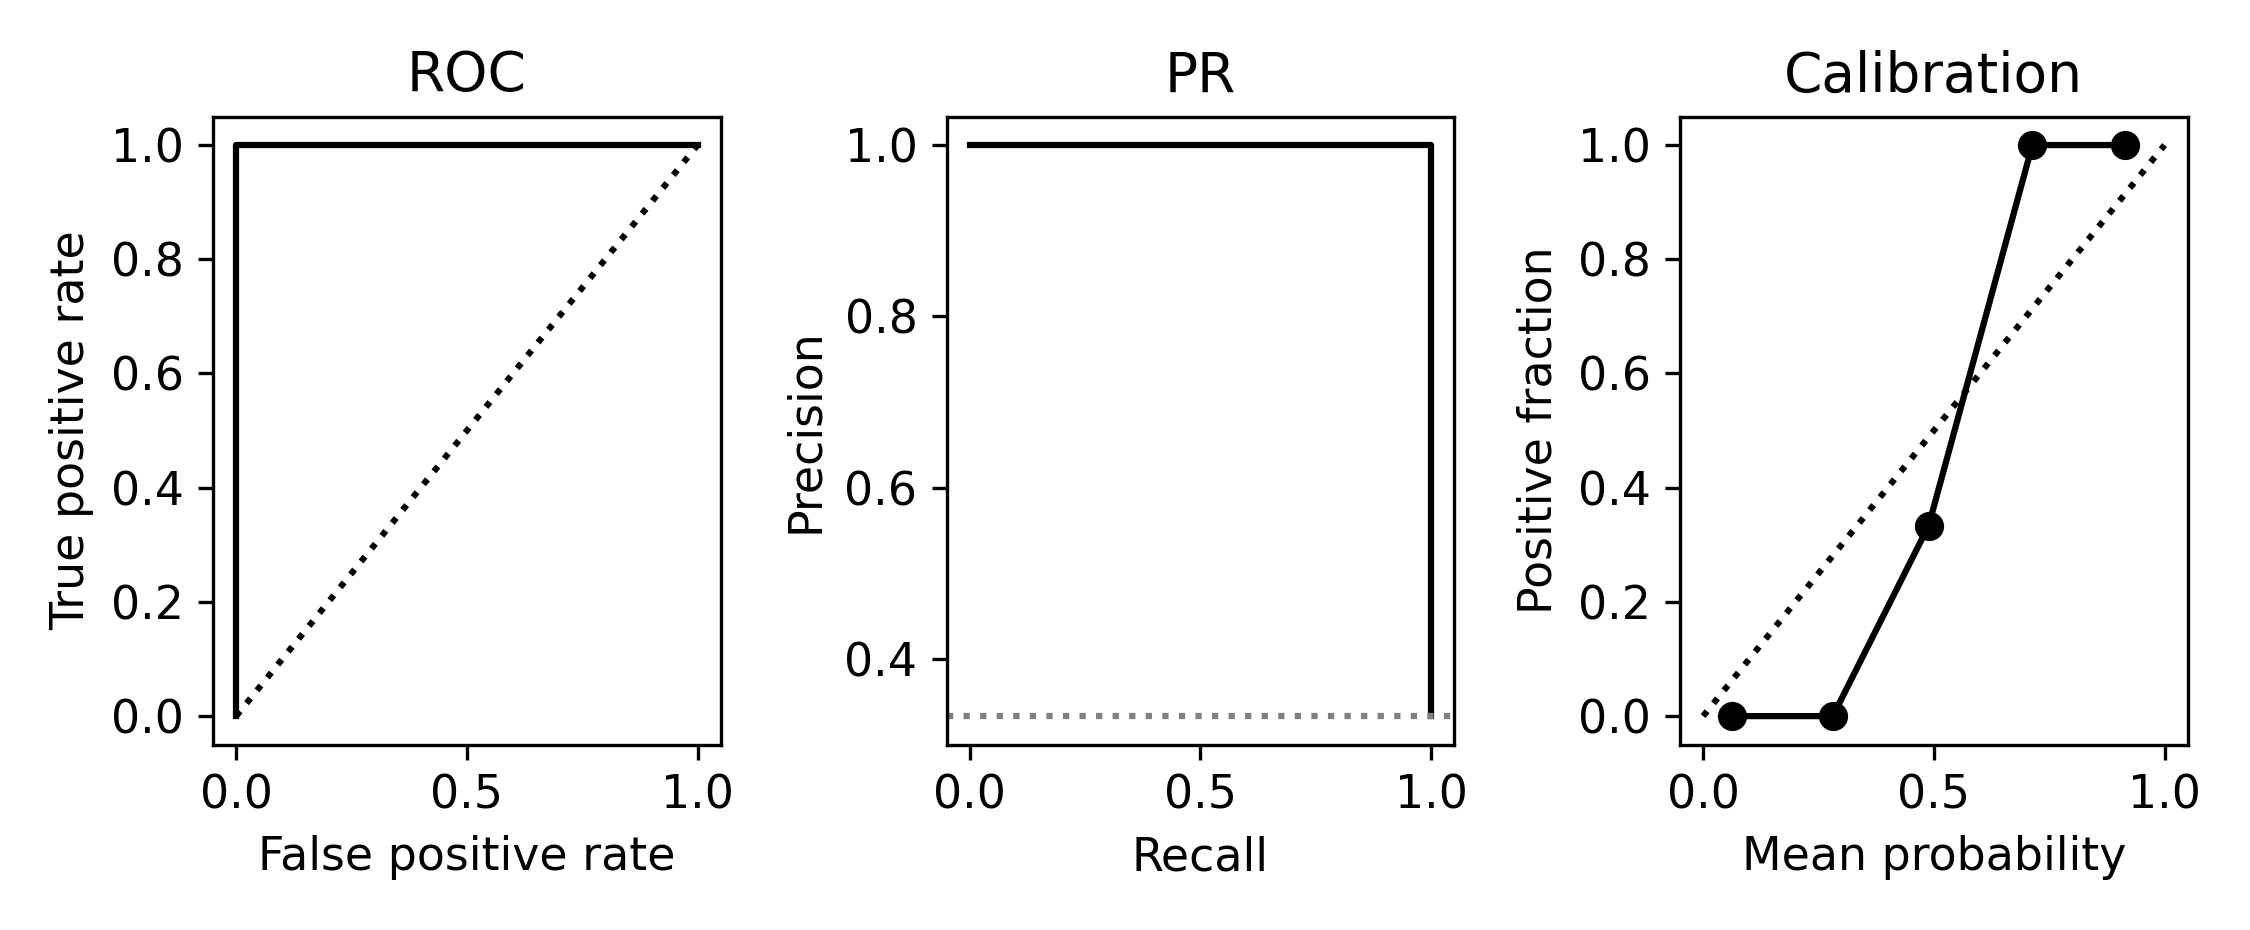

In [6]:
# 앞 셀의 값을 사용해 axes[1].set(xlabel="Recall",ylabel="Precision",title="PR") 동작을 수행합니다. 코드에 쓰인 괄호·인자·들여쓰기를 유지합니다.
axes[1].set(xlabel="Recall",ylabel="Precision",title="PR")

# 앞 셀의 값을 사용해 axes[2].plot(prob,obs,"ko-") 동작을 수행합니다. 코드에 쓰인 괄호·인자·들여쓰기를 유지합니다.
axes[2].plot(prob,obs,"ko-")

# 앞 셀의 값을 사용해 axes[2].plot([0,1],[0,1],"k:") 동작을 수행합니다. 코드에 쓰인 괄호·인자·들여쓰기를 유지합니다.
axes[2].plot([0,1],[0,1],"k:")

# 앞 셀의 값을 사용해 axes[2].set(xlabel="Mean probability",ylabel="Positive fraction",title="Calibration") 동작을 수행합니다. 코드에 쓰인 괄호·인자·들여쓰기를 유지합니다.
axes[2].set(xlabel="Mean probability",ylabel="Positive fraction",title="Calibration")

# 실제 계산한 그림을 저장하고 표시합니다. 축·기호·범례의 의미는 이 실습의 결과 해설과 대조합니다.
figure(OUT,"roc_pr")

# 앞 셀의 값을 사용해 pd.DataFrame({"true":truth.to_numpy(),"probability":p}).to_csv(OUT/"roc_pr.csv",index=Fals 동작을 수행합니다. 코드에 쓰인 괄호·인자·들여쓰기를 유지합니다.
pd.DataFrame({"true":truth.to_numpy(),"probability":p}).to_csv(OUT/"roc_pr.csv",index=False)

# 실제 계산한 수치를 결과 파일과 셀 출력에 기록합니다. 다른 데이터나 미실행 모델의 성능으로 해석하지 않습니다.
report(OUT,"roc_pr",{"test_n":len(te),"prevalence":truth.mean(),
    "ROC_AUC":roc_auc_score(truth,p),"AP":average_precision_score(truth,p),
    "Brier":brier_score_loss(truth,p)})

## 그림과 결과 해석

ROC는 FPR/TPR, PR은 Recall/Precision이다. 보정 곡선은 구간 평균 확률과 실제 양성 비율을 비교한다. 비어 있는 구간은 표시되지 않는다.

작은 테스트 세트와 구간화 결과는 불안정할 수 있다. 보정 곡선 자체가 보정 처리를 수행한 것은 아니다.